In [194]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress


## **Data Loading**

In [195]:
# Variables to change
pick_task = ["ENS", "MEG"]
task = "MEG"

ID = "EPC1003"
subject = 1
block = 1

In [ ]:
if task == "ENS" : 
    data = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/Comportement_FRINT_ENS_num{subject}_{ID}.csv", index_col=2)
elif task == "MEG" :
    data = pd.read_csv(f"données MEG/FRINT_MEG_S{subject}.csv", index_col = 0)
    events = pd.read_csv(f"events MEG/events_S{subject}_B{block}.csv", index_col = 0)
    print(events)
data

,rotangle_1,rotangle_2,rotangle_3,rotangle_4,rotangle_5,rotangle_6,rotangle_7,presangle_1,presangle_2,presangle_3,...,rotations_6,rotations_7,target,presavg,optimal,GenMean,Block,Seqlen,final_angle,trial_rt
Var1,,,,,,,,,,,,,,,,,,,,,
0,27.928289,36.791598,36.834987,NaN,NaN,NaN,NaN,27.928289,81.791598,36.834987,...,NaN,NaN,33.862260,46.614746,33.862260,39.141487,1,3,46.904922,46.904922
1,135.934354,136.680783,131.169997,167.511924,165.670694,NaN,NaN,135.934354,136.680783,176.169997,...,NaN,NaN,147.059534,148.908459,147.059534,149.277866,1,5,-9.436148,-9.436148
2,63.570402,25.454216,53.672990,51.923355,34.939138,46.674841,16.13517,18.570402,70.454216,53.672990,...,0.0,-45.0,42.033324,52.323002,42.033324,48.449604,1,7,31.418148,31.418148
3,72.711491,86.261984,71.581581,83.315137,84.422517,NaN,NaN,72.711491,86.261984,71.581581,...,NaN,NaN,79.675806,71.763093,79.675806,95.536653,1,5,80.679587,80.679587
4,177.625190,147.369345,148.235593,180.178499,168.748825,NaN,NaN,222.625190,147.369345,103.235593,...,NaN,NaN,164.563284,143.563391,164.563284,178.499029,1,5,-5.990595,-5.990595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,183.218973,187.214822,184.420427,NaN,NaN,NaN,NaN,228.218973,187.214822,229.420427,...,NaN,NaN,4.950984,36.259298,4.950984,178.790084,10,3,12.414293,12.414293
356,161.457978,164.641661,156.093550,152.227008,162.825610,NaN,NaN,206.457978,164.641661,201.093550,...,NaN,NaN,159.458498,6.994098,159.458498,158.306800,10,5,-17.241459,-17.241459
357,126.522803,119.893945,152.858656,148.326851,106.904621,NaN,NaN,171.522803,119.893945,197.858656,...,NaN,NaN,130.865724,170.318355,130.865724,119.981359,10,5,-32.788492,-32.788492


## **Functions**

In [197]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2 

## **Dataframe creation for the one subject**

### dataframe in degrees

In [198]:
if task == "ENS" : 
    df_filtered = data[data["stimulus_rotations"].notna()]
    df_filtered = df_filtered.drop(columns=["rt","target", "survey_id", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus", "failed_tuto1", "failed_tuto2", "failed_tuto3"])
    df_filtered.reset_index(drop=True, inplace=True)
    df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
    df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['score'] = df_filtered['score'].astype(int)
    df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

    df_filtered = df_filtered.dropna(subset=["final_angle"])

elif task == "MEG" :
    data.columns = data.columns.str.strip()
    df_filtered = data.copy()
    # Exemple: sélection des colonnes rotangle_1 à rotangle_7
    rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
    rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
    presangle_cols = [f'presangle_{i}' for i in range(1, 8)]

    df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
    df_filtered["length of sequence"] = df_filtered["Seqlen"]

    df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)

    df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
    df_filtered.reset_index(drop=True, inplace=True)
    df_filtered = df_filtered.dropna(subset=["final_angle"])

### dataframe in radian

In [199]:
if task == "ENS" :
    df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations"])
    df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

    df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) 
    df_filtered["target"] = df_radian["target"].apply(np.rad2deg) 

    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
    
elif task == "MEG" : 
    df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
    df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
    df_radian["target"] = np.deg2rad(df_filtered['target'])
    df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
    df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])

    df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))


    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 


df_radian

,Block,trial_rt,length of sequence,final_angle,target,GenMean,expected_angles_wo_rot,stimulus_rotations,presented_angles,expected_angles,mean_rotation
0,1,46.904922,3,0.818645,0.591008,0.683148,0.813581,"[0.0, -0.7853981633974483, 0.0]","[0.48744059296065856, 1.4275326845204115, 0.64...","[0.48744059296065856, 0.6421345211229632, 0.64...",-0.261799
1,1,-9.436148,5,-0.164692,2.566673,2.605390,2.598943,"[0.0, 0.0, -0.7853981633974483, 0.785398163397...","[2.3725020447441887, 2.385529684063234, 3.0747...","[2.3725020447441887, 2.385529684063234, 2.2893...",-0.157080
2,1,31.418148,7,0.548350,0.733620,0.845605,0.913209,"[0.7853981633974483, -0.7853981633974483, 0.0,...","[0.3241146562245449, 1.2296580337808862, 0.936...","[1.1095128196219932, 0.44425987038343806, 0.93...",-0.112200
3,1,80.679587,5,1.408124,1.390605,1.667429,1.252502,"[0.0, 0.0, 0.0, 0.0, 0.7853981633974483]","[1.269054917271835, 1.50555563783374, 1.249334...","[1.269054917271835, 1.50555563783374, 1.249334...",0.157080
4,1,-5.990595,5,-0.104556,2.872171,3.115396,2.505654,"[-0.7853981633974483, 0.0, 0.7853981633974483,...","[3.885542556571171, 2.5720802878046403, 1.8018...","[3.1001443931737227, 2.5720802878046403, 2.587...",0.157080
...,...,...,...,...,...,...,...,...,...,...,...
355,10,12.414293,3,0.216670,0.086411,3.120476,0.632844,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[3.983172493846442, 3.2675150473736605, 4.0041...","[3.197774330448994, 3.2675150473736605, 3.2187...",-0.523599
356,10,-17.241459,5,-0.300920,2.783076,2.762975,0.122070,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[3.603371474732437, 2.8735390660390165, 3.5097...","[2.8179733113349883, 2.8735390660390165, 2.724...",-0.471239
357,10,-32.788492,5,-0.572267,2.284038,2.094070,2.972616,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[2.99363764639656, 2.092544100785376, 3.453284...","[2.2082394829991117, 2.092544100785376, 2.6678...",-0.628319
358,10,-47.852911,1,-0.835191,2.377622,2.755009,0.021428,[-0.7853981633974483],[3.1630204179108925],[2.3776222545134442],-0.785398


## **Metadata Exploration**

### basic informations 

In [200]:
if task == "ENS" : 
    print(f"the participant's score is {df_radian["score"].sum()}/2000")

In [201]:
if task == "ENS" : 
    print(f"participant's gender is : {data["responses"][4][7]}")

In [202]:
if task == "ENS" : 
    print(f"participant's age is between : {data["responses"][3][7:12]}")

### rotation proportions

In [203]:
angles_lists = df_filtered["stimulus_rotations"]
all_angles = set()
for lst in angles_lists:
    all_angles.update(lst)
angle_presence = {}
total_lists = len(angles_lists)
for angle in all_angles:
    count = sum(angle in lst for lst in angles_lists)
    angle_presence[angle] = count / total_lists * 100  # en %

print("Proportion of sequences that contain each 3 angles (%) :")
for angle, pct in angle_presence.items():
    print(f"Angle {angle}: {pct:.1f}%")
all_occurrences = [angle for lst in angles_lists for angle in lst]
freq = Counter(all_occurrences)

print("\ntotal frequency of each angle (number of occurence) :")
for angle, count in freq.items():
    print(f"Angle {angle}: {count}")



Proportion of sequences that contain each 3 angles (%) :
Angle 0.0: 70.0%
Angle -45.0: 67.2%
Angle 45.0: 65.8%

total frequency of each angle (number of occurence) :
Angle 0.0: 481
Angle -45.0: 483
Angle 45.0: 476


In [204]:
df_filtered['length_of_sequence'] = df_filtered['stimulus_rotations'].apply(len)
only_45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == 45.0 for angle in x))]
only_minus45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == -45.0 for angle in x))]

only_minus45_filtered = only_minus45[only_minus45['length_of_sequence'] > 1]
only_45_filtered = only_45[only_45['length_of_sequence'] > 1]

print("Sequences 100% of +45° and length > 1 :")
print("there are", len(only_45), "sequences 100% of +45° in total, and", len(only_45_filtered),"sequences of 1 element +45°")

print("\nSequences 100% of -45° and length > 1 :")
print("there are", len(only_minus45), "sequences 100% of -45° in total, and", len(only_minus45_filtered),"sequences of 1 element -45°")

Sequences 100% of +45° and length > 1 :
there are 30 sequences 100% of +45° in total, and 4 sequences of 1 element +45°

Sequences 100% of -45° and length > 1 :
there are 33 sequences 100% of -45° in total, and 7 sequences of 1 element -45°


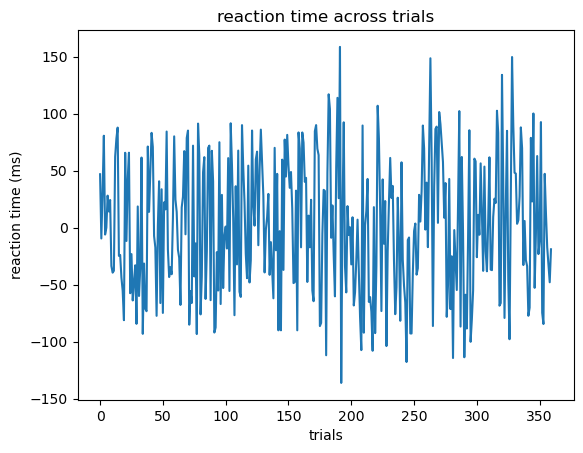

In [205]:
plt.plot(df_filtered["trial_rt"])
plt.title("reaction time across trials")
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.show()

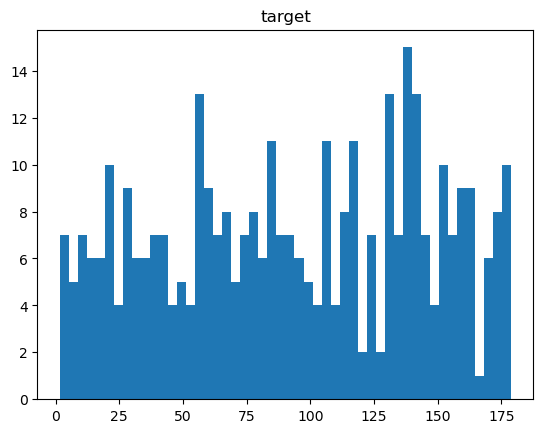

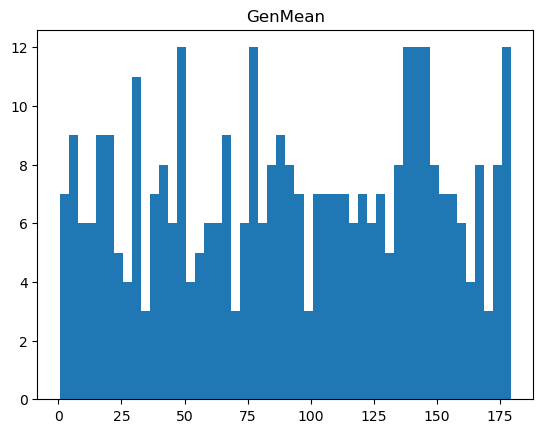

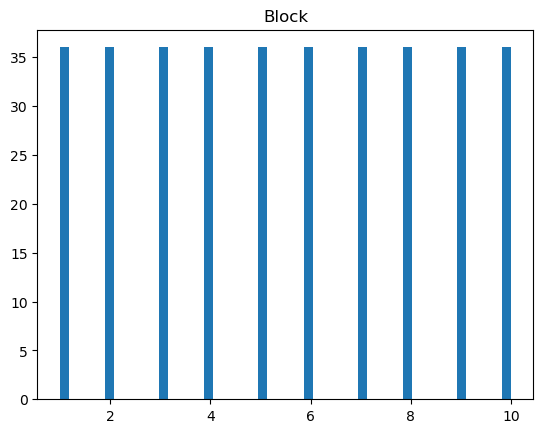

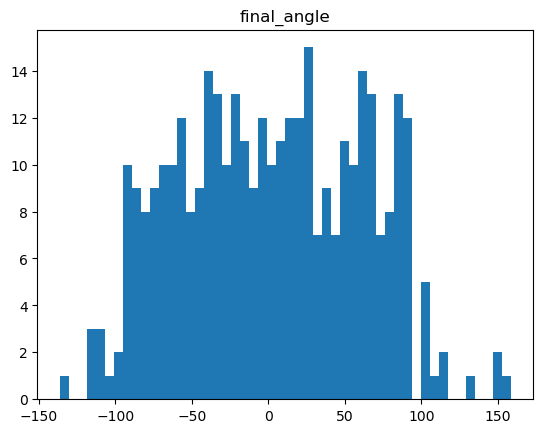

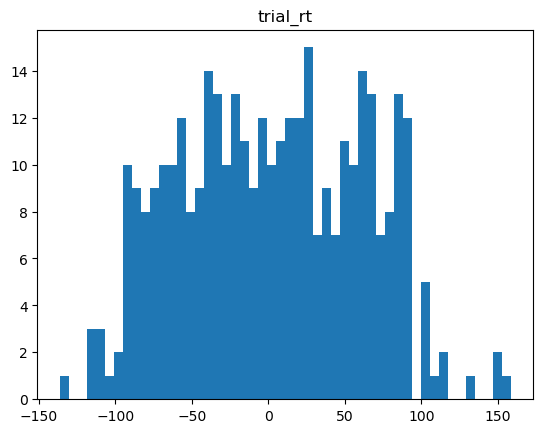

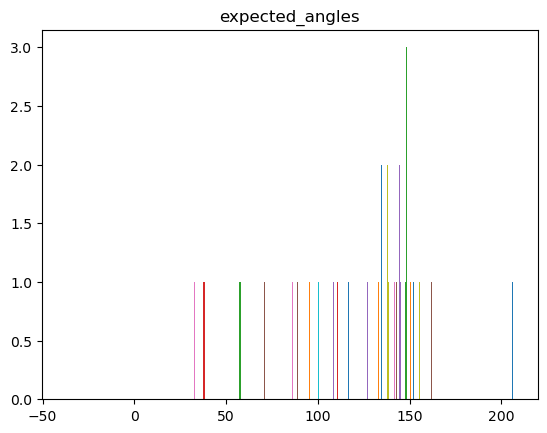

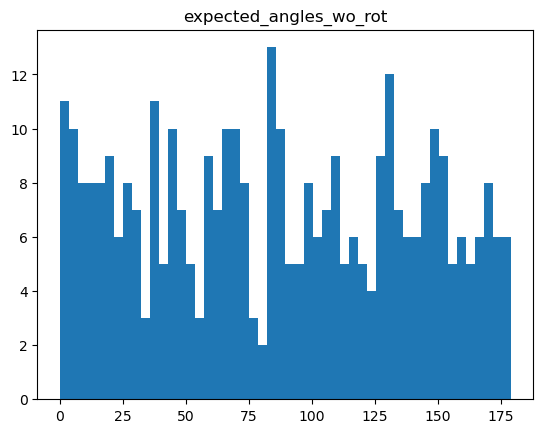

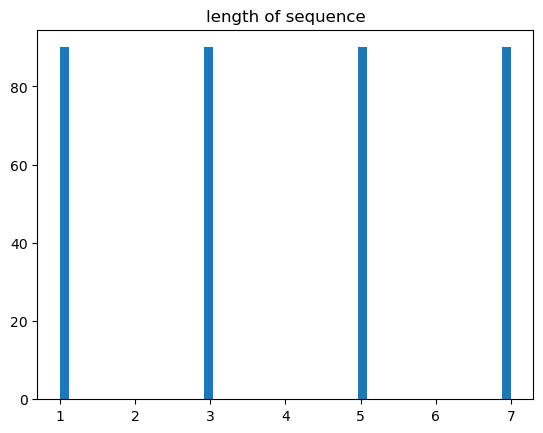

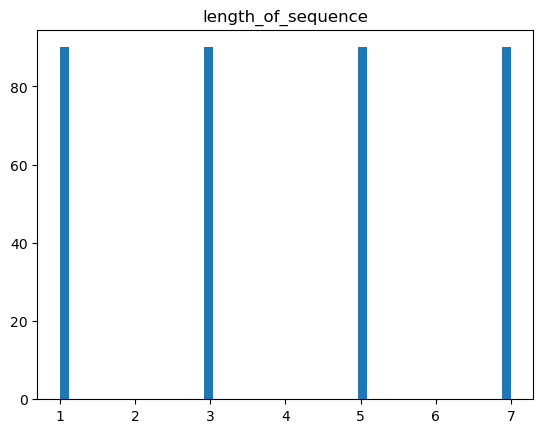

In [206]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## **Performances**

### Did the participants responded well ? (error between final angle and the target angle) 

In [207]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) 
df_filtered["error_to_target"] = df_radian["error_to_target"].apply(np.rad2deg)

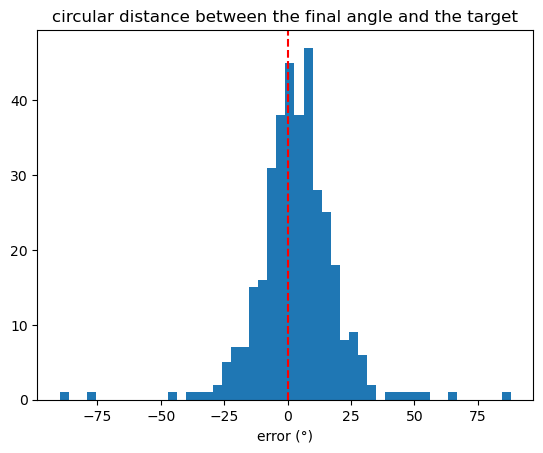

In [208]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("error (°)")
plt.title("circular distance between the final angle and the target")
plt.show()

### Did the participants ignored the rotations ? (take into account only the orientations that they have seen, without rotating the stimulus)

In [209]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  

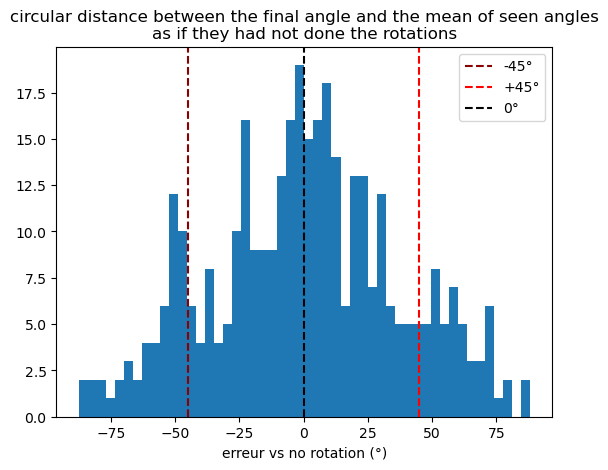

In [210]:
plt.hist(np.rad2deg(df_radian["error_wo_rotation"]), bins=50)
plt.axvline(-45, color='darkred', linestyle='--', label="-45°") 
plt.axvline(45, color='red', linestyle='--', label="+45°") 
plt.axvline(0, color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (°)")
plt.title("circular distance between the final angle and the mean of seen angles\nas if they had not done the rotations")
plt.legend()
plt.show()

### Mean rotations VS errors

mean rotation vs error to target : the response error

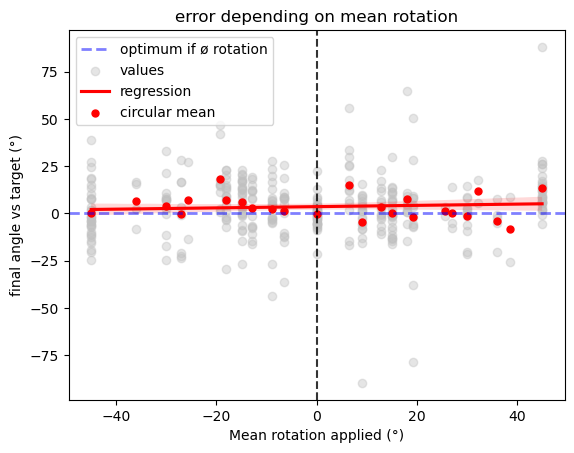

In [211]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum if ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_to_target"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("final angle vs target (°)")
plt.title("error depending on mean rotation")
plt.legend()
plt.show()

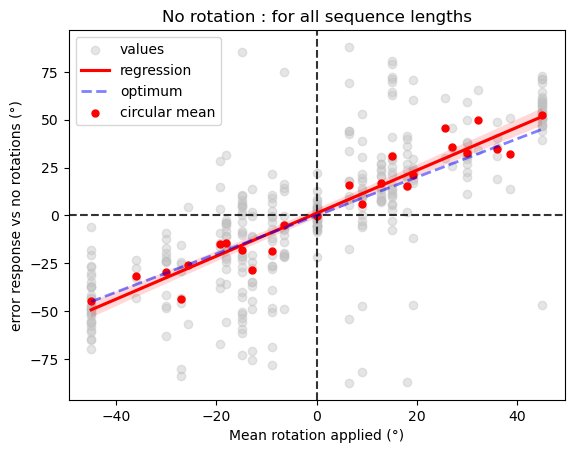

In [212]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
borne = x["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")
plt.title("No rotation : for all sequence lengths")
plt.legend()
plt.show()

plot for different sequence lengths

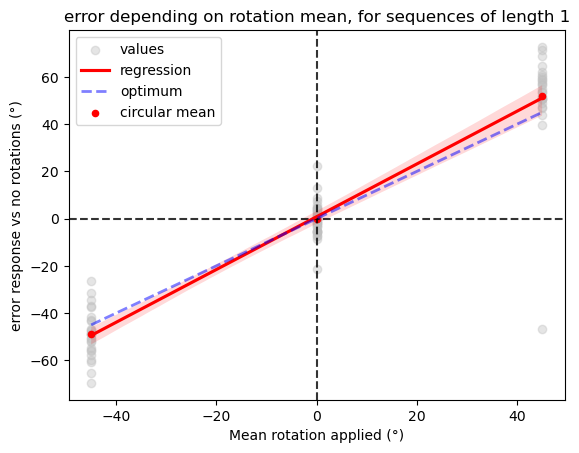

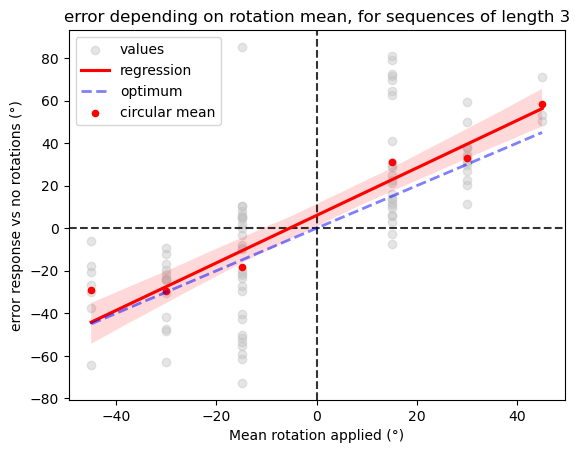

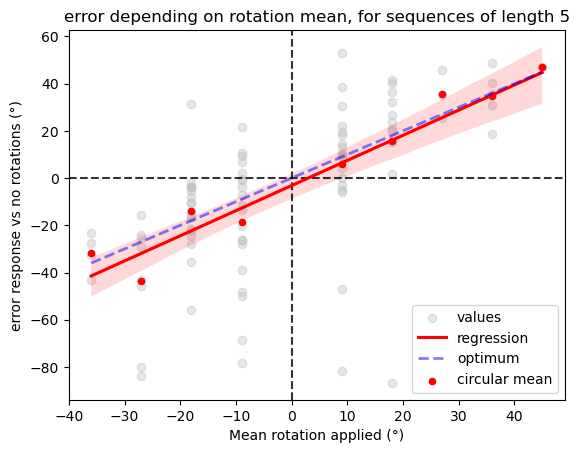

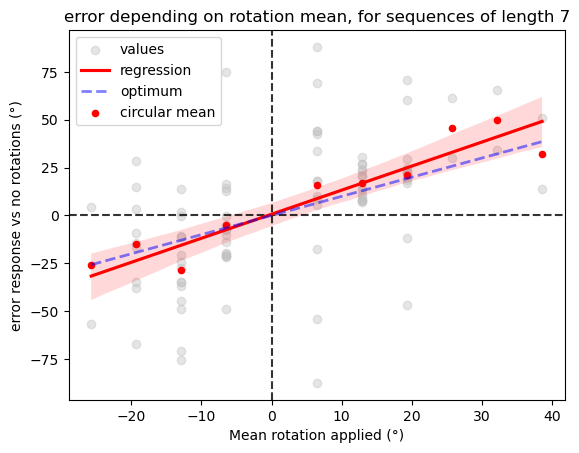

In [213]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x=df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation"].apply(np.rad2deg), y=df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="circular mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("error response vs no rotations (°)")    
    plt.title(f"error depending on rotation mean, for sequences of length {seqlen}")
    plt.legend()
    plt.show()

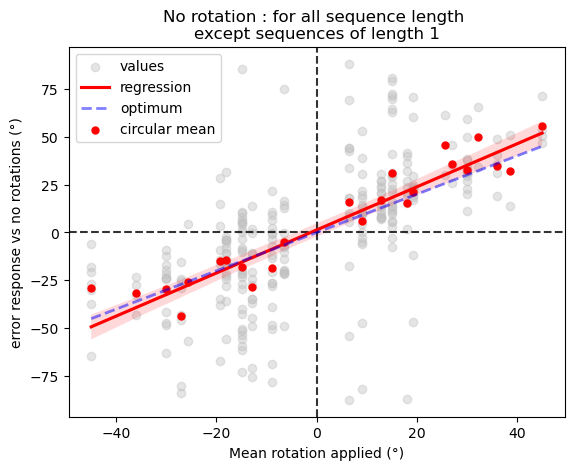

In [214]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x=df["mean_rotation"].apply(np.rad2deg), y=df["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")    
plt.title("No rotation : for all sequence length \nexcept sequences of length 1")
plt.legend()
plt.show()

## **Reaction time**

### RT vs error

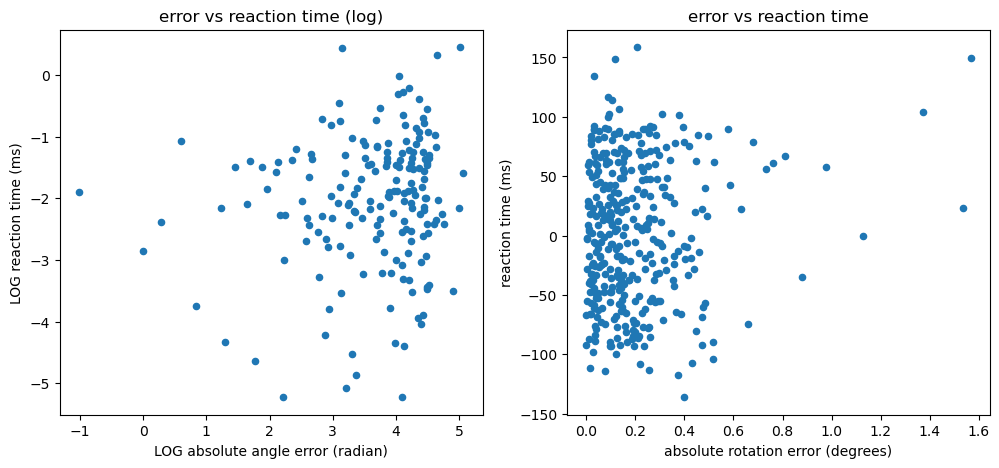

In [215]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG absolute angle error (radian)")
plt.ylabel("LOG reaction time (ms)")
plt.title("error vs reaction time (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("absolute rotation error (degrees)")
plt.ylabel("reaction time (ms)")
plt.title("error vs reaction time")
plt.show()

### error vs le temps

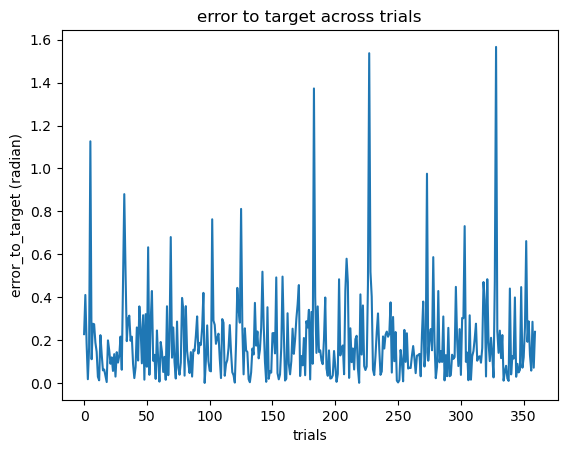

In [216]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("trials")
plt.ylabel("error_to_target (radian)")
plt.title("error to target across trials")
plt.show()

### Score vs time

In [217]:
plt.plot(df_radian["score"], '.', color = "darkviolet")
plt.xlabel("trials")
plt.ylabel("score")
plt.title("score across trials")
plt.show()

KeyError: 'score'

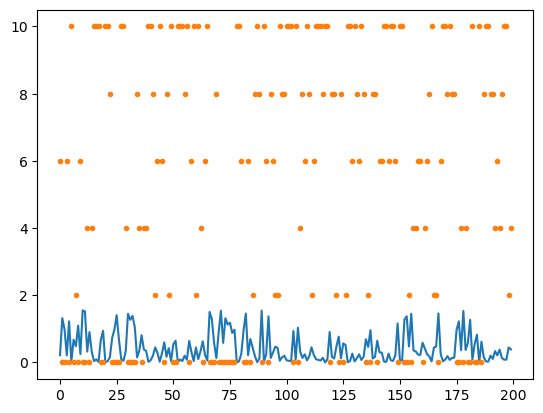

In [ ]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.plot(df_radian["score"], '.')


### RT vs time

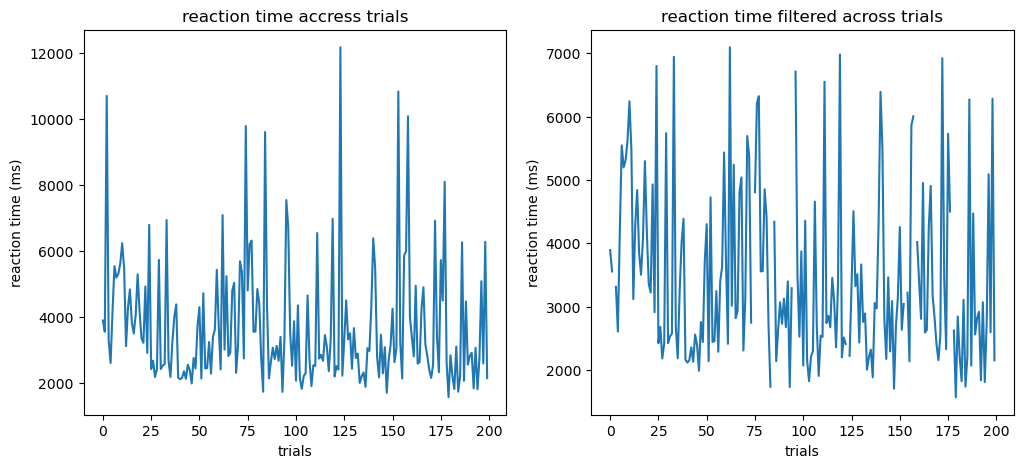

In [ ]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time accress trials")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time filtered across trials")
plt.show()

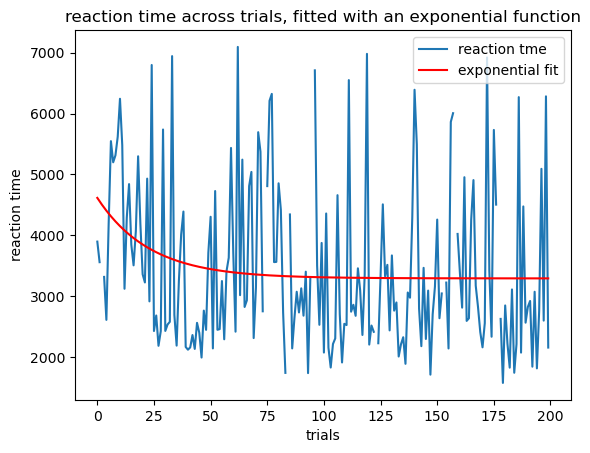

In [ ]:
from scipy.optimize import curve_fit

y = rt_filtered.values.astype(float)
x = np.arange(len(y))

mask = np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# exponential model
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(
    exp_model,
    x_clean,
    y_clean,
    p0=[1000, 0.01, 2000],   # best guesses
    maxfev=10000          
)

a, b, c = params

y_fit_full = exp_model(x, a, b, c)

plt.plot(x, y, label="reaction tme")
plt.plot(x, y_fit_full, "r", label="exponential fit")
plt.legend()
plt.xlabel("trials")
plt.ylabel("reaction time")
plt.title("reaction time across trials, fitted with an exponential function")
plt.show()

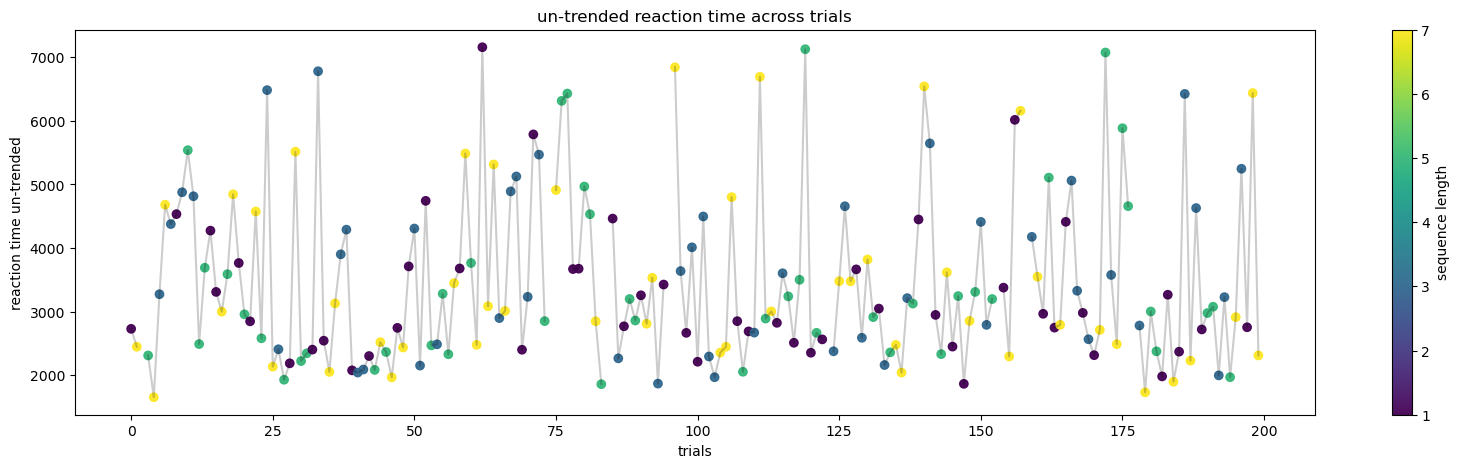

In [ ]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit_full
residuals = y - y_fit_full + np.mean(y_fit_full)
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="sequence length")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("trials")
plt.ylabel("reaction time un-trended")
plt.title("un-trended reaction time across trials")
plt.show()


### RT vs seq length

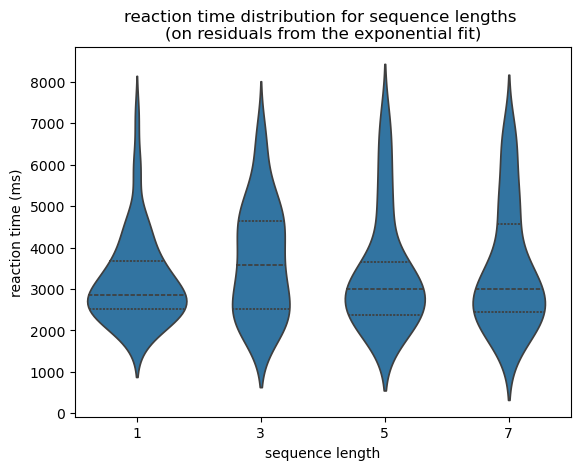

In [ ]:
sns.violinplot(x=seq, y=residuals, inner="quartile")

plt.xlabel("sequence length")
plt.ylabel("reaction time (ms)")
plt.title("reaction time distribution for sequence lengths \n(on residuals from the exponential fit)")

plt.show()

## **Events check**

In [ ]:
if task == "MEG" :
    order = -1
    error_var = 0
    for i in range(len(events["event_code"])) : 
        if events["event_code"][i] == 144 : 
            num = events["event_code"][i-1]
            order += 1
            if num == 129 : 
                num = 1
            elif num == 131 :
                num = 3
            elif num == 133 :
                num = 5 
            elif num == 135 : 
                num = 7 
            else : 
                print("error")
            
            if not num == df_radian[df_radian["Block"]==block]["length of sequence"][order] :
                error_var +=1
                print("False")

    if error_var != 0 : 
        print(f"there is {error_var} errors in the order of sequences between the behavioral data and the MEG triggers")
    else : 
        print("There are no errors in the order of sequences between the behavioral data and the MEG triggers")